# Slow-wind bias: does the metric reward the over-forecast?

Step 5 of `docs/next_steps.md`. The submitted linear model's forecasts are shifted down by
δ km/s in three sets of runs: the true slow-wind runs (an oracle), runs whose last speed is
below 450 km/s (realistic), and every run (a control). δ is chosen on the fold's training
runs, per lead, or in hindsight. Six yearly folds, official metric. Study
`python -m training.slow_bias`; write-up `docs/slow_bias.md`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from training import slow_bias as sb

flat = pd.read_csv(sb.EXPERIMENTS / "slow_bias.csv", dtype={"fold": str})
rows = {}
for (y, v), g in flat.groupby(["fold", "variant"], sort=False):
    rec = g.iloc[0].drop(["fold", "variant"]).dropna().to_dict()
    rows.setdefault(y, {})[v] = rec["value"] if list(rec) == ["value"] else rec
table, grid = sb.summarize(rows, pilot=True)


over 6 fold(s); slow-run residual (obs - forecast): 2019 -18.5, 2020 -39.5, 2021 -47.5, 2022 -61.5, 2023 -41.7, 2024 -71.0 km/s



shift chosen on the training runs:
                   vs reference folds won    rmse   trmse slow wind    CME stream arrival fast stream intermediate   delta  share precision recall passes
oracle fitted           -0.0179         6 -0.0341 -0.0006   -0.1087 0.0000         0.0000      0.0000       0.0000 24.1667 0.3036    1.0000 1.0000   True
oracle lead bias        -0.0247         6 -0.0477 -0.0012   -0.1465 0.0000         0.0000      0.0000       0.0000 29.6148 0.3036    1.0000 1.0000   True
last<450 fitted          0.0000         0  0.0000  0.0000    0.0000 0.0000         0.0000      0.0000       0.0000  0.0000 0.6764    0.4096 0.9652  False
last<450 lead bias       0.0079         1 -0.0228  0.0393   -0.0819 0.0097         0.0523      0.0126       0.0124 11.3762 0.6764    0.4096 0.9652  False
all runs fitted          0.0000         0  0.0000  0.0000    0.0000 0.0000         0.0000      0.0000       0.0000  0.0000 1.0000    0.3036 1.0000  False
all runs lead bias       0.0130         


hindsight grid (vs reference, geometric mean over folds):
set    all runs  last<450  oracle
delta                            
0        0.0000    0.0000  0.0000
5        0.0018    0.0018 -0.0062
10       0.0074    0.0062 -0.0111
15       0.0167    0.0133 -0.0148
20       0.0297    0.0229 -0.0172
25       0.0462    0.0349 -0.0183
30       0.0661    0.0492 -0.0183
35       0.0891    0.0656 -0.0171
40       0.1151    0.0840 -0.0149
45       0.1438    0.1042 -0.0116
50       0.1750    0.1261 -0.0074
55       0.2085    0.1495 -0.0022
60       0.2442    0.1743  0.0037
65       0.2818    0.2004  0.0104
70       0.3213    0.2276  0.0178
75       0.3623    0.2559  0.0258
80       0.4049    0.2852  0.0345



... its RMSE and TRMSE parts, oracle:
         rmse   trmse  slow wind
delta                           
0      0.0000  0.0000     0.0000
5     -0.0117 -0.0006    -0.0355
10    -0.0210 -0.0010    -0.0637
15    -0.0280 -0.0011    -0.0846
20    -0.0327 -0.0009    -0.0985
25    -0.0351 -0.0006    -0.1056
30    -0.0354  0.0000    -0.1064
35    -0.0336  0.0009    -0.1010
40    -0.0298  0.0019    -0.0897
45    -0.0242  0.0032    -0.0730
50    -0.0170  0.0047    -0.0511
55    -0.0081  0.0064    -0.0242
60     0.0021  0.0083     0.0072
65     0.0138  0.0103     0.0429
70     0.0266  0.0126     0.0827
75     0.0406  0.0151     0.1263
80     0.0557  0.0177     0.1734


## The hindsight grid

S_final relative to the reference (geometric mean over the six folds), by shift and set of runs; and the oracle's RMSE and TRMSE parts.

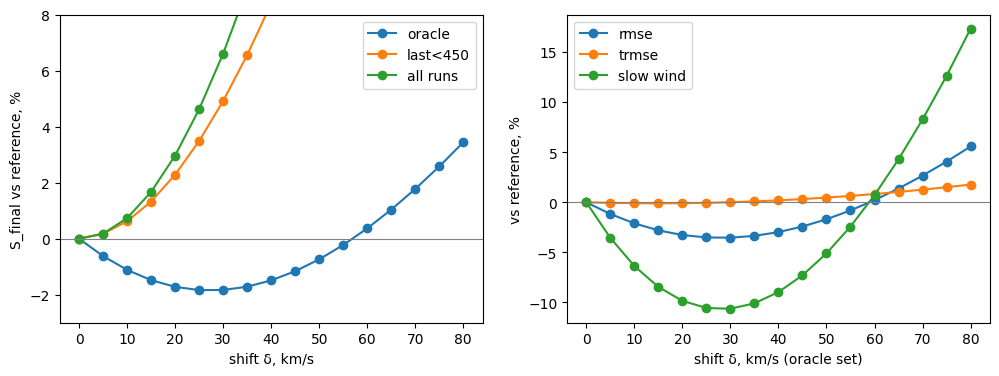

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in sb.SETS:
    g = grid[grid.set == name]
    axes[0].plot(g.delta, 100 * g["vs reference"], marker="o", label=name)
axes[0].axhline(0, color="grey", lw=0.8)
axes[0].set_ylim(-3, 8)
axes[0].set_xlabel("shift δ, km/s")
axes[0].set_ylabel("S_final vs reference, %")
axes[0].legend()
g = grid[grid.set == "oracle"]
for col in ("rmse", "trmse", "slow wind"):
    axes[1].plot(g.delta, 100 * g[col], marker="o", label=col)
axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set_xlabel("shift δ, km/s (oracle set)")
axes[1].set_ylabel("vs reference, %")
axes[1].legend()
plt.show()

## The slow runs' over-forecast by fold

In [3]:
pd.Series({y: rows[y]["slow residual"] for y in sorted(rows)},
          name="slow-run mean residual, km/s (observed - forecast)").round(1)

2019   -18.5
2020   -39.5
2021   -47.5
2022   -61.5
2023   -41.7
2024   -71.0
Name: slow-run mean residual, km/s (observed - forecast), dtype: float64

## Conclusion

- **The over-forecast is a cost, not what the metric rewards:** shifting the true slow-wind
  runs down is 1.8% better (one shift) to 2.5% better (per lead) on all six folds, through
  RMSE, with TRMSE unchanged.
- **Detection is the problem:** "last speed below 450" catches 97% of slow runs, but only 41%
  of the runs it flags stay slow, and shifting it loses.
- **The global lean is right:** shifting every run down loses on the tail term.
- **The ceiling is about 2–2.5%** even with perfect detection. Step 2's gate, P(no arrival)
  from the Bayes stream model, is a realistic detector, and can reach only part of it.